# 02 — Comparative Analysis

This notebook loads per-game CSV logs generated by the Pygame **AI vs AI** mode
and produces comparative visualizations across all matchups.

**Supported matchups:**
- ResNet vs XGBoost (base and RL-finetuned)
- ResNet vs Minimax
- XGBoost vs Minimax

> **Google Colab:** Upload your CSV files or mount Google Drive.

In [111]:
import os

# Load CSVs from local data/ subfolders
data_root = os.path.join(os.path.dirname(os.getcwd()), 'data')
if not os.path.isdir(data_root):
    data_root = '../data'  # fallback for running from notebooks/

csv_files = []  # (matchup_folder, filename) pairs
for folder in sorted(os.listdir(data_root)):
    folder_path = os.path.join(data_root, folder)
    if os.path.isdir(folder_path):
        for f in sorted(os.listdir(folder_path)):
            if f.endswith('.csv'):
                csv_files.append((folder, f))

print(f'Found {len(csv_files)} game files in {data_root}')
for folder in sorted(set(f[0] for f in csv_files)):
    count = sum(1 for f in csv_files if f[0] == folder)
    print(f'  {folder}/  ({count} games)')

Found 300 game files in /home/yfour/FinalProject/data
  ResNet_RL_vs_Minimax/  (50 games)
  ResNet_RL_vs_XGBoost_RL/  (50 games)
  ResNet_vs_Minimax/  (50 games)
  ResNet_vs_XGBoost/  (50 games)
  XGBoost_RL_vs_Minimax/  (50 games)
  XGBoost_vs_Minimax/  (50 games)


In [112]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import re
from collections import defaultdict

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

## 1. Load & Parse Game Logs

Each game is a separate CSV. Filenames encode the matchup:
- `ResNet_vs_XGBoost_001.csv`
- `ResNet_RL_vs_XGBoost_RL_002.csv`
- `ResNet_vs_Minimax_003.csv`
- `game_004.csv` (legacy format)

The last row of each file contains the winner as `Winner: AgentName`.

In [113]:
all_moves = []
winners = []
skipped = []

for game_id, (matchup, filename) in enumerate(csv_files, start=1):
    filepath = os.path.join(data_root, matchup, filename)

    try:
        df = pd.read_csv(filepath)
    except Exception as e:
        skipped.append((filename, str(e)))
        continue

    if len(df) == 0:
        skipped.append((filename, 'empty file'))
        continue

    # Parse winner from last row
    last_row = df.iloc[-1]
    winner_field = str(last_row.get('Score_or_Probability', ''))
    winner = 'Unknown'

    if 'Winner:' in winner_field:
        winner = winner_field.split('Winner:')[1].strip()
        df = df.iloc[:-1]  # Remove winner row from moves

    winners.append({
        'Game_ID': game_id,
        'Filename': filename,
        'Matchup': matchup,
        'Winner': winner,
    })

    # Keep only valid move rows
    df = df[df['Turn_Number'].notna() & (df['Turn_Number'] != '')].copy()
    df['Game_ID'] = game_id
    df['Matchup'] = matchup
    all_moves.append(df)

moves_df = pd.concat(all_moves, ignore_index=True)
results_df = pd.DataFrame(winners)

# Convert types
moves_df['Turn_Number'] = pd.to_numeric(moves_df['Turn_Number'], errors='coerce').astype(int)
moves_df['Move'] = pd.to_numeric(moves_df['Move'], errors='coerce').astype(int)
moves_df['Compute_Time_ms'] = pd.to_numeric(moves_df['Compute_Time_ms'], errors='coerce')

matchups = results_df['Matchup'].unique()
agents = moves_df['Agent'].unique()

print(f'Total games loaded: {len(results_df)}')
print(f'Total moves: {len(moves_df)}')
print(f'Matchup types: {list(matchups)}')
print(f'Agents seen: {list(agents)}')
if skipped:
    print(f'Skipped files: {skipped}')

for m in matchups:
    count = (results_df['Matchup'] == m).sum()
    print(f'  {m}: {count} games')

Total games loaded: 300
Total moves: 5856
Matchup types: ['ResNet_RL_vs_Minimax', 'ResNet_RL_vs_XGBoost_RL', 'ResNet_vs_Minimax', 'ResNet_vs_XGBoost', 'XGBoost_RL_vs_Minimax', 'XGBoost_vs_Minimax']
Agents seen: ['ResNet (RL)', 'Minimax', 'XGBoost (RL)', 'ResNet', 'XGBoost']
  ResNet_RL_vs_Minimax: 50 games
  ResNet_RL_vs_XGBoost_RL: 50 games
  ResNet_vs_Minimax: 50 games
  ResNet_vs_XGBoost: 50 games
  XGBoost_RL_vs_Minimax: 50 games
  XGBoost_vs_Minimax: 50 games


## 2. Win Rate Analysis — Per Matchup

Win rates broken down by each matchup type. This shows how each agent
performs against different opponents.

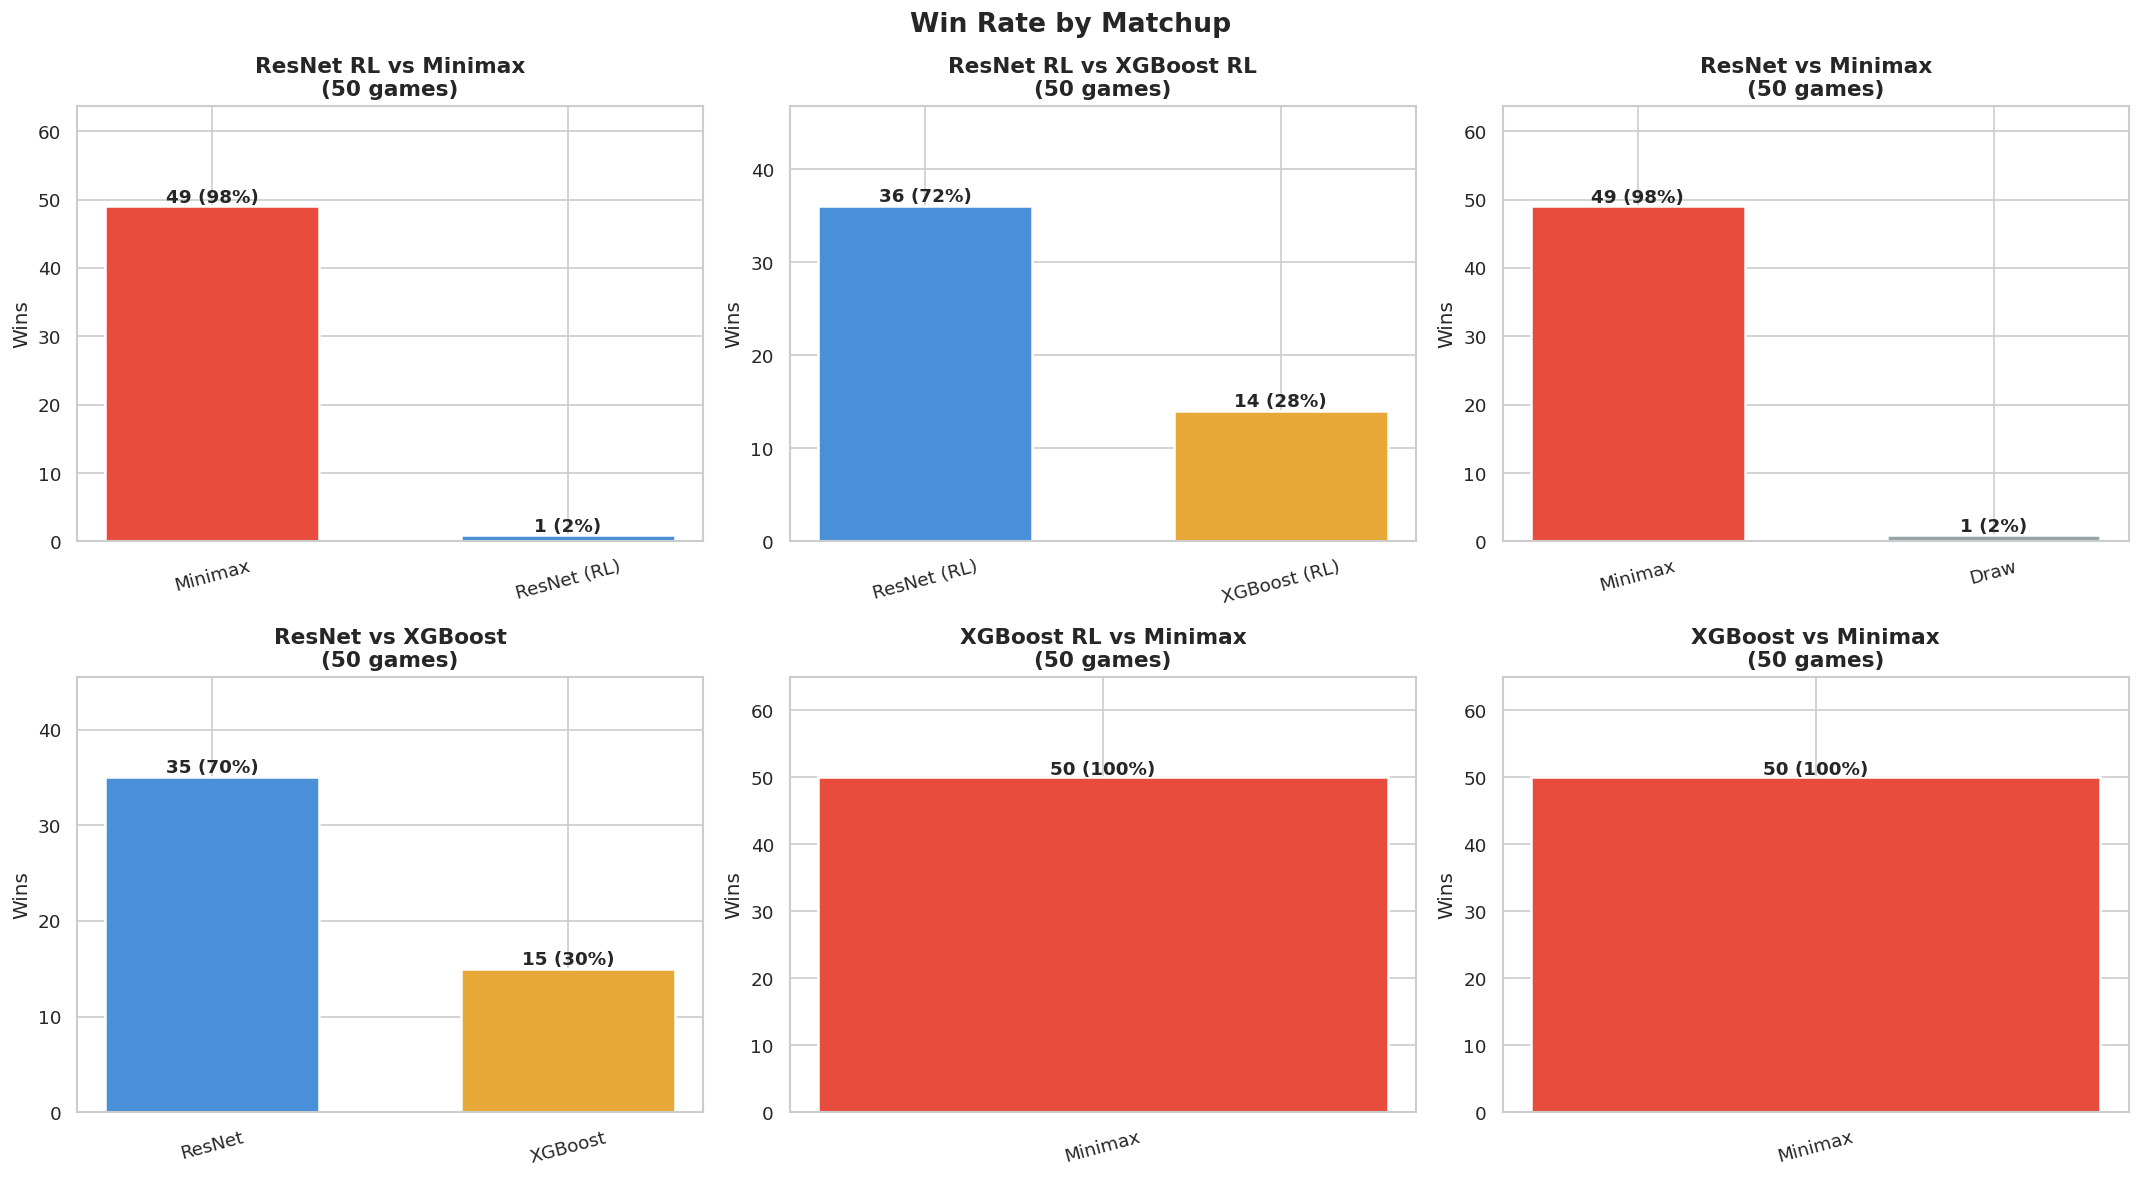

In [114]:
# Color palette for agents
AGENT_COLORS = {
    'ResNet': '#4A90D9',
    'ResNet (RL)': '#1E5FAA',
    'XGBoost': '#E8A838',
    'XGBoost (RL)': '#C47F17',
    'Minimax': '#E74C3C',
    'Draw': '#95A5A6',
    'Unknown': '#666666',
}

def get_color(agent_name):
    """Get color for an agent, with fallback."""
    for key, color in AGENT_COLORS.items():
        if key in agent_name:
            return color
    return '#666666'


n_matchups = len(matchups)
cols_grid = min(3, n_matchups)
rows_grid = (n_matchups + cols_grid - 1) // cols_grid

fig, axes = plt.subplots(rows_grid, cols_grid, figsize=(6 * cols_grid, 5 * rows_grid))
axes = np.atleast_2d(axes)

for idx, matchup in enumerate(matchups):
    r, c = divmod(idx, cols_grid)
    ax = axes[r][c]

    mdf = results_df[results_df['Matchup'] == matchup]
    win_counts = mdf['Winner'].value_counts()
    total = len(mdf)

    bar_colors = [get_color(w) for w in win_counts.index]
    bars = ax.bar(win_counts.index, win_counts.values, color=bar_colors,
                  edgecolor='white', linewidth=1.5, width=0.6)

    for i, (label, val) in enumerate(zip(win_counts.index, win_counts.values)):
        pct = 100 * val / total
        ax.text(i, val + 0.5, f'{val} ({pct:.0f}%)', ha='center', fontweight='bold', fontsize=11)

    ax.set_ylabel('Wins')
    title = matchup.replace('_', ' ')
    ax.set_title(f'{title}\n({total} games)', fontsize=13, fontweight='bold')
    ax.set_ylim(0, max(win_counts.values) * 1.3)
    ax.tick_params(axis='x', rotation=15)

# Hide empty subplots
for idx in range(n_matchups, rows_grid * cols_grid):
    r, c = divmod(idx, cols_grid)
    axes[r][c].set_visible(False)

plt.suptitle('Win Rate by Matchup', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Agent Win Rate Comparison (Cross-Matchup)

How does each agent perform across all its matchups?
This is the core of the comparative study.

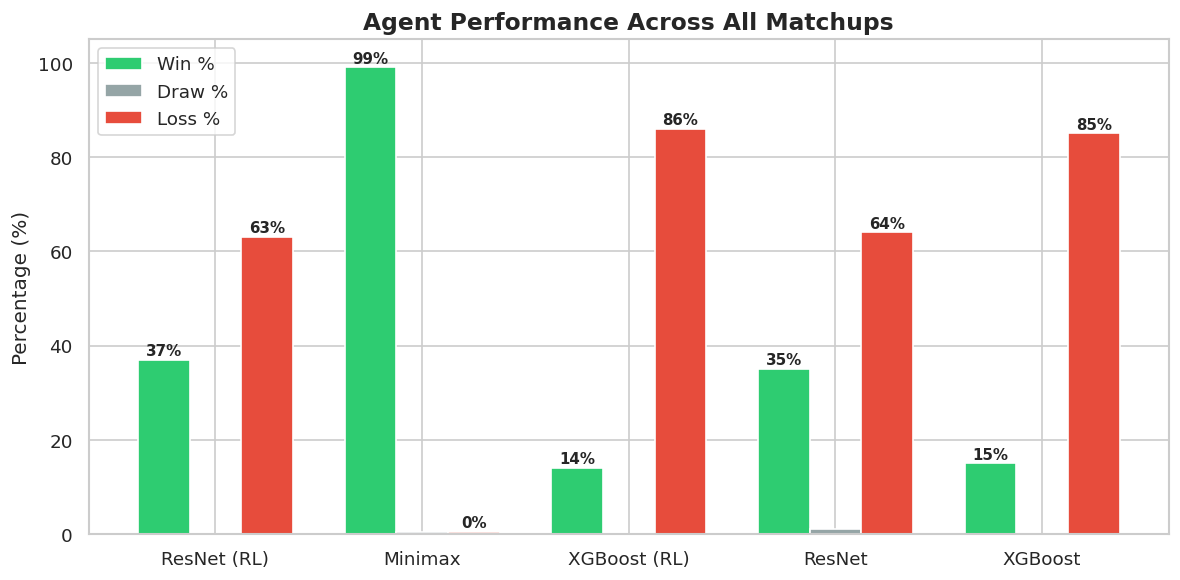

In [115]:
# Build per-agent statistics across all matchups
agent_stats = {}

for agent in agents:
    # Games where this agent participated
    agent_games = moves_df[moves_df['Agent'] == agent]['Game_ID'].unique()
    agent_results = results_df[results_df['Game_ID'].isin(agent_games)]
    total = len(agent_results)

    if total == 0:
        continue

    wins = (agent_results['Winner'] == agent).sum()
    draws = (agent_results['Winner'] == 'Draw').sum()
    losses = total - wins - draws

    agent_stats[agent] = {
        'total': total,
        'wins': wins,
        'losses': losses,
        'draws': draws,
        'win_rate': 100 * wins / total,
        'draw_rate': 100 * draws / total,
        'loss_rate': 100 * losses / total,
    }

if agent_stats:
    stat_agents = list(agent_stats.keys())
    win_rates = [agent_stats[a]['win_rate'] for a in stat_agents]
    draw_rates = [agent_stats[a]['draw_rate'] for a in stat_agents]
    loss_rates = [agent_stats[a]['loss_rate'] for a in stat_agents]

    x = np.arange(len(stat_agents))
    width = 0.25

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(x - width, win_rates, width, label='Win %', color='#2ecc71')
    ax.bar(x, draw_rates, width, label='Draw %', color='#95a5a6')
    ax.bar(x + width, loss_rates, width, label='Loss %', color='#e74c3c')

    ax.set_ylabel('Percentage (%)')
    ax.set_title('Agent Performance Across All Matchups', fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(stat_agents, fontsize=11)
    ax.legend()
    ax.set_ylim(0, 105)

    # Add percentage labels
    for i, agent in enumerate(stat_agents):
        ax.text(i - width, win_rates[i] + 1, f'{win_rates[i]:.0f}%',
                ha='center', fontsize=9, fontweight='bold')
        ax.text(i + width, loss_rates[i] + 1, f'{loss_rates[i]:.0f}%',
                ha='center', fontsize=9, fontweight='bold')

    plt.tight_layout()
    plt.show()

## 4. Base vs Fine-Tuned (RL) Comparison

Did reinforcement learning improve the models? Compare base and RL-finetuned
versions of each agent.

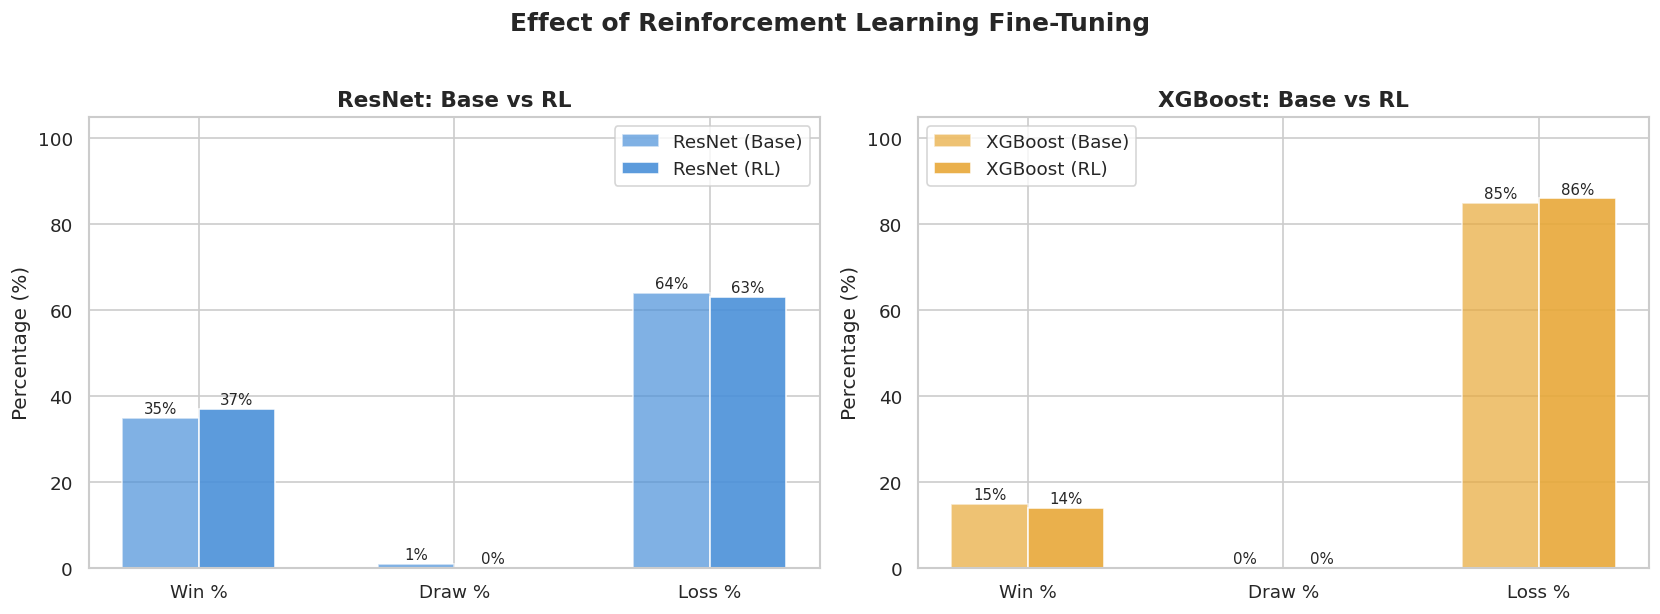

In [116]:
# Group agents into base vs RL pairs
base_agents = [a for a in agents if '(RL)' not in a and a not in ('Minimax', 'Draw')]
rl_agents = [a for a in agents if '(RL)' in a]

pairs = []
for base in base_agents:
    rl_name = f'{base} (RL)'
    if rl_name in rl_agents:
        pairs.append((base, rl_name))

if pairs:
    fig, axes = plt.subplots(1, len(pairs), figsize=(7 * len(pairs), 5))
    if len(pairs) == 1:
        axes = [axes]

    for ax, (base_name, rl_name) in zip(axes, pairs):
        categories = ['Win %', 'Draw %', 'Loss %']
        base_vals = [
            agent_stats.get(base_name, {}).get('win_rate', 0),
            agent_stats.get(base_name, {}).get('draw_rate', 0),
            agent_stats.get(base_name, {}).get('loss_rate', 0),
        ]
        rl_vals = [
            agent_stats.get(rl_name, {}).get('win_rate', 0),
            agent_stats.get(rl_name, {}).get('draw_rate', 0),
            agent_stats.get(rl_name, {}).get('loss_rate', 0),
        ]

        x = np.arange(len(categories))
        w = 0.3
        ax.bar(x - w/2, base_vals, w, label=f'{base_name} (Base)', color=get_color(base_name), alpha=0.7)
        ax.bar(x + w/2, rl_vals, w, label=f'{rl_name}', color=get_color(rl_name), alpha=0.9)

        ax.set_ylabel('Percentage (%)')
        ax.set_title(f'{base_name}: Base vs RL', fontsize=13, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels(categories)
        ax.legend()
        ax.set_ylim(0, 105)

        # Labels
        for i in range(len(categories)):
            ax.text(i - w/2, base_vals[i] + 1, f'{base_vals[i]:.0f}%', ha='center', fontsize=9)
            ax.text(i + w/2, rl_vals[i] + 1, f'{rl_vals[i]:.0f}%', ha='center', fontsize=9)

    plt.suptitle('Effect of Reinforcement Learning Fine-Tuning', fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print('No base vs RL pairs found in the data.\n'
          'Upload games from both Base and Fine-tuned modes to see this comparison.')

## 5. Computation Time Analysis

Compare inference speed across agents. ResNet uses GPU-accelerated neural
network inference, XGBoost uses tree-based prediction, and Minimax uses
recursive search that grows with game complexity.

/tmp/ipykernel_69101/3994126742.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(box_data, labels=agents, patch_artist=True, showfliers=False)


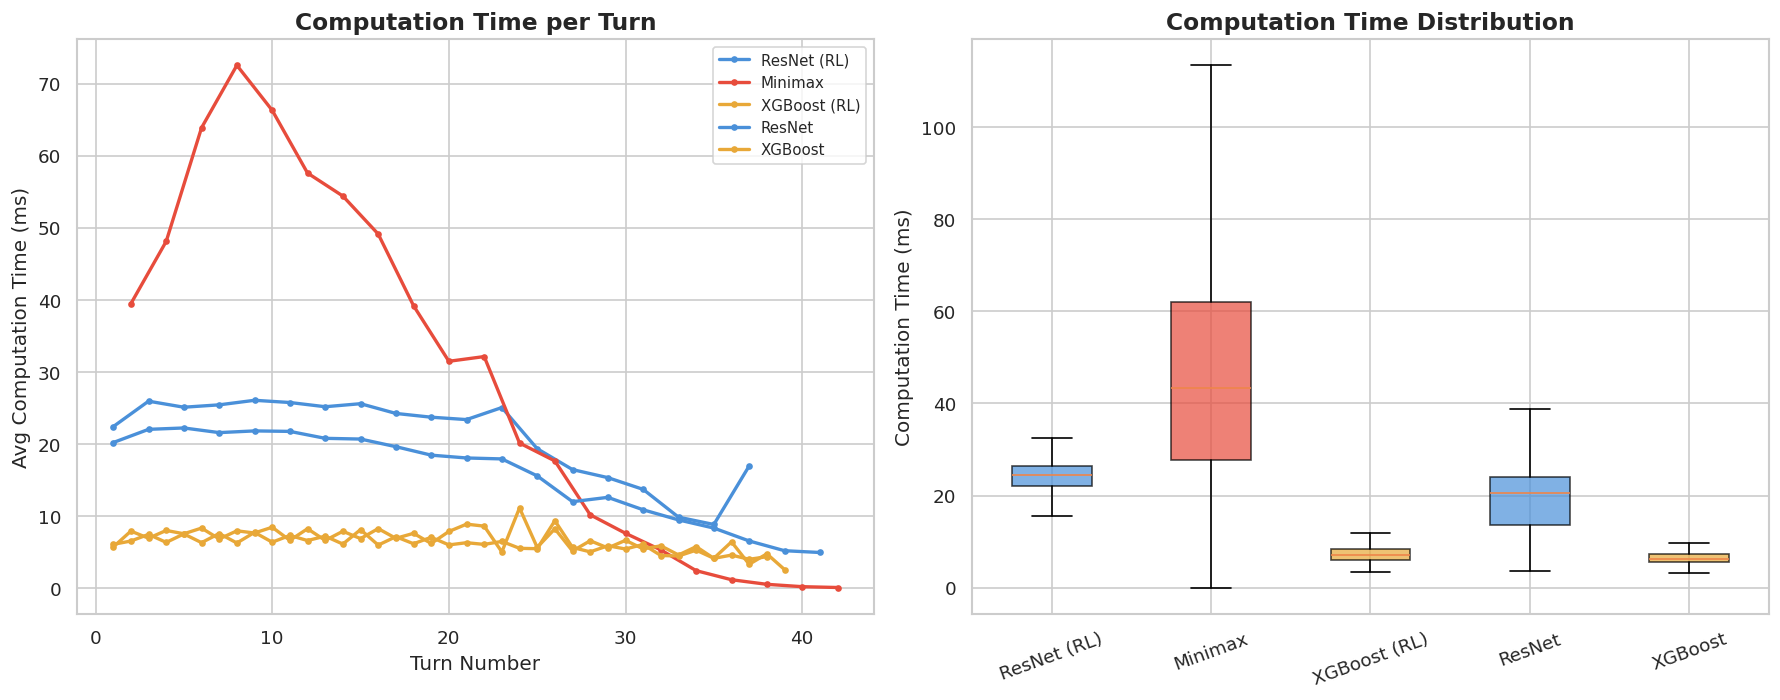

Agent                 Mean (ms)     Median        Std        Min        Max
------------------------------------------------------------------------
ResNet (RL)               24.31      24.38       7.20       6.03     124.06
Minimax                   49.29      43.44      38.06       0.04     279.33
XGBoost (RL)               7.40       7.09       2.49       3.33      35.18
ResNet                    19.44      20.49       7.45       3.67     103.56
XGBoost                    6.62       6.28       2.76       2.55      70.34


In [117]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Line plot: computation time per turn
for agent in agents:
    agent_data = moves_df[moves_df['Agent'] == agent]
    avg_by_turn = agent_data.groupby('Turn_Number')['Compute_Time_ms'].mean()
    axes[0].plot(avg_by_turn.index, avg_by_turn.values,
                 label=agent, color=get_color(agent), linewidth=2,
                 marker='o', markersize=3)

axes[0].set_xlabel('Turn Number')
axes[0].set_ylabel('Avg Computation Time (ms)')
axes[0].set_title('Computation Time per Turn', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=9)

# Box plot: no outlier dots, linear scale
box_data = [moves_df[moves_df['Agent'] == a]['Compute_Time_ms'].dropna().values for a in agents]
bp = axes[1].boxplot(box_data, labels=agents, patch_artist=True, showfliers=False)
for patch, agent in zip(bp['boxes'], agents):
    patch.set_facecolor(get_color(agent))
    patch.set_alpha(0.7)
axes[1].set_ylabel('Computation Time (ms)')
axes[1].set_title('Computation Time Distribution', fontsize=14, fontweight='bold')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

# Print table
print(f'{"Agent":<20} {"Mean (ms)":>10} {"Median":>10} {"Std":>10} {"Min":>10} {"Max":>10}')
print('-' * 72)
for agent in agents:
    t = moves_df[moves_df['Agent'] == agent]['Compute_Time_ms'].dropna()
    print(f'{agent:<20} {t.mean():>10.2f} {t.median():>10.2f} {t.std():>10.2f} {t.min():>10.2f} {t.max():>10.2f}')

## 6. Move Distribution Heatmaps

Which columns does each agent prefer? Center-column preference indicates
strategic understanding (center columns control more winning lines).

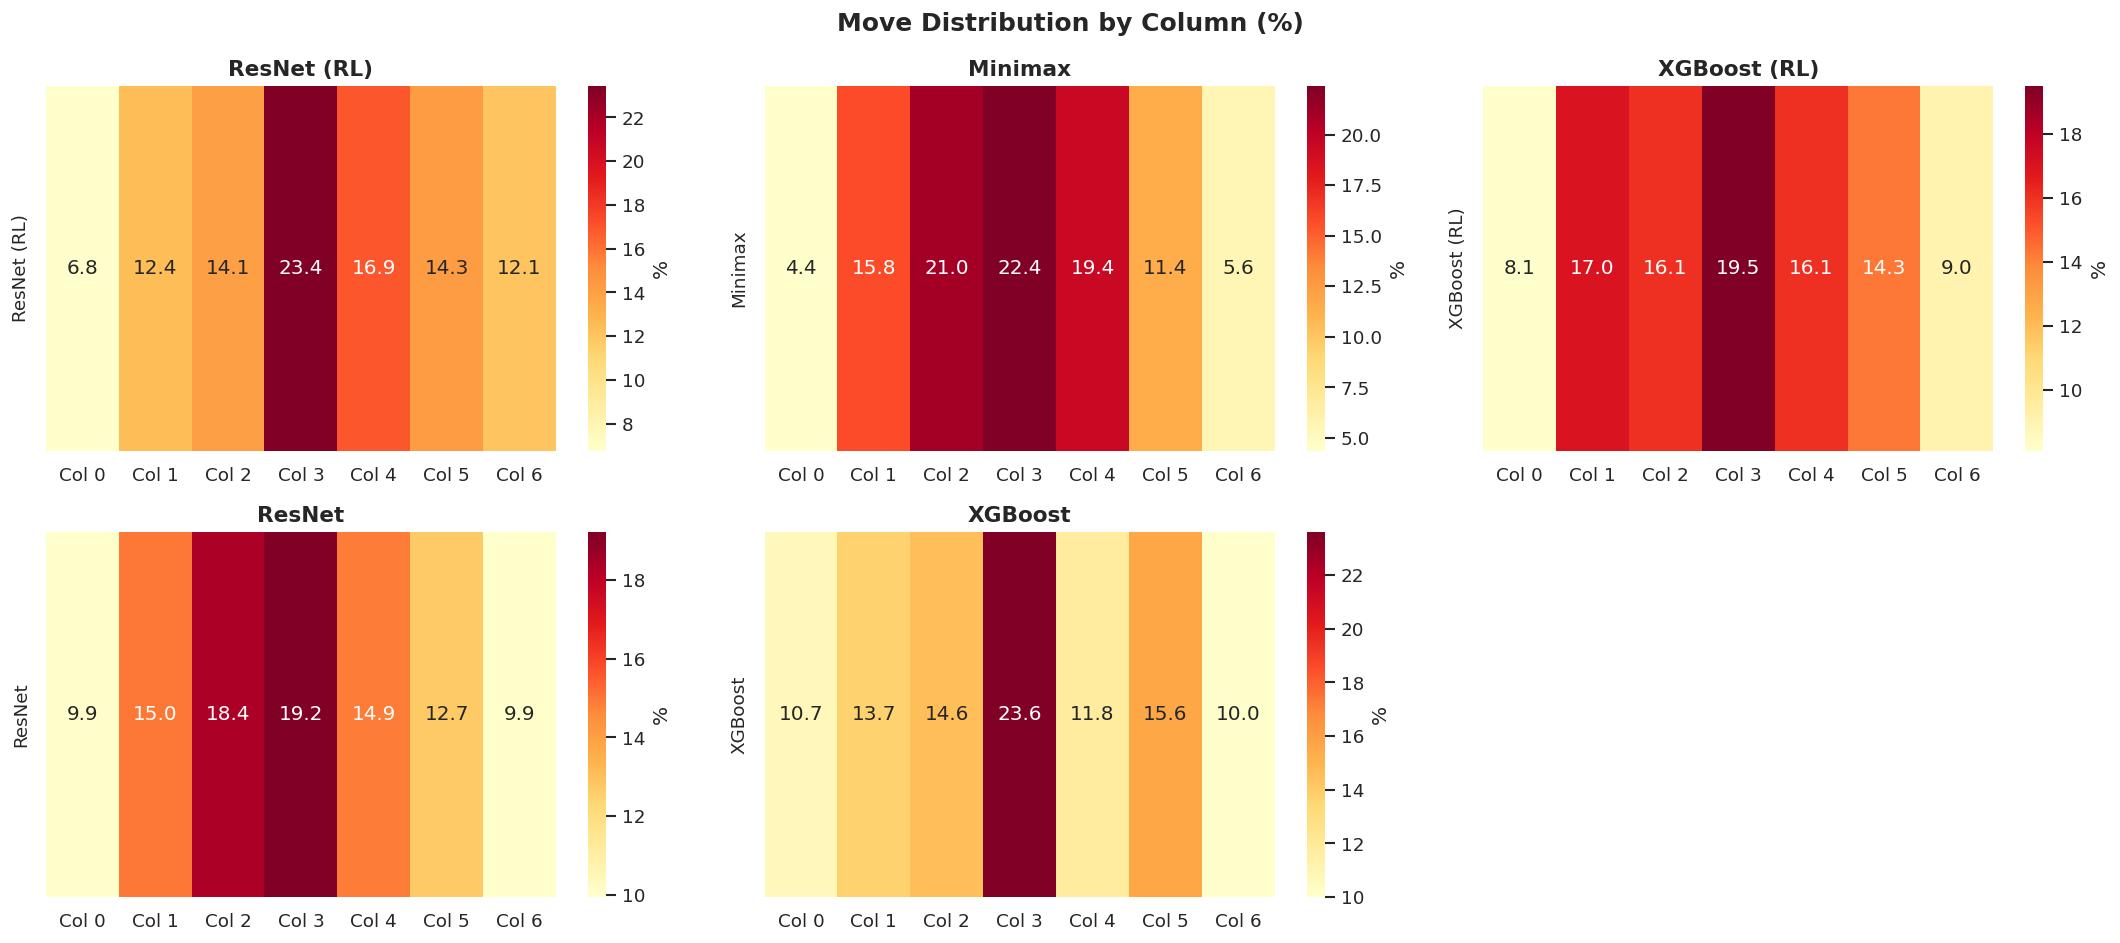

In [118]:
n_agents = len(agents)
cols_per_row = min(3, n_agents)
rows = (n_agents + cols_per_row - 1) // cols_per_row
fig, axes = plt.subplots(rows, cols_per_row, figsize=(6 * cols_per_row, 4 * rows))
if n_agents == 1:
    axes = np.array([[axes]])
axes = np.atleast_2d(axes)

for i, agent in enumerate(agents):
    r, c = divmod(i, cols_per_row)
    ax = axes[r][c]
    agent_data = moves_df[moves_df['Agent'] == agent]
    col_counts = agent_data['Move'].value_counts().reindex(range(7), fill_value=0)
    col_pct = (col_counts / col_counts.sum() * 100).values.reshape(1, -1)

    sns.heatmap(col_pct, annot=True, fmt='.1f', cmap='YlOrRd',
                xticklabels=[f'Col {c}' for c in range(7)],
                yticklabels=[agent], ax=ax, annot_kws={'size': 12},
                cbar_kws={'label': '%'})
    ax.set_title(f'{agent}', fontsize=13, fontweight='bold')

# Hide empty subplots
for i in range(n_agents, rows * cols_per_row):
    r, c = divmod(i, cols_per_row)
    axes[r][c].set_visible(False)

plt.suptitle('Move Distribution by Column (%)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Game Length Analysis

Longer games may indicate more defensive play or closer skill levels.
Short games suggest one agent is significantly stronger.

/tmp/ipykernel_69101/1963933779.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(matchup_lengths, labels=matchup_labels, patch_artist=True)


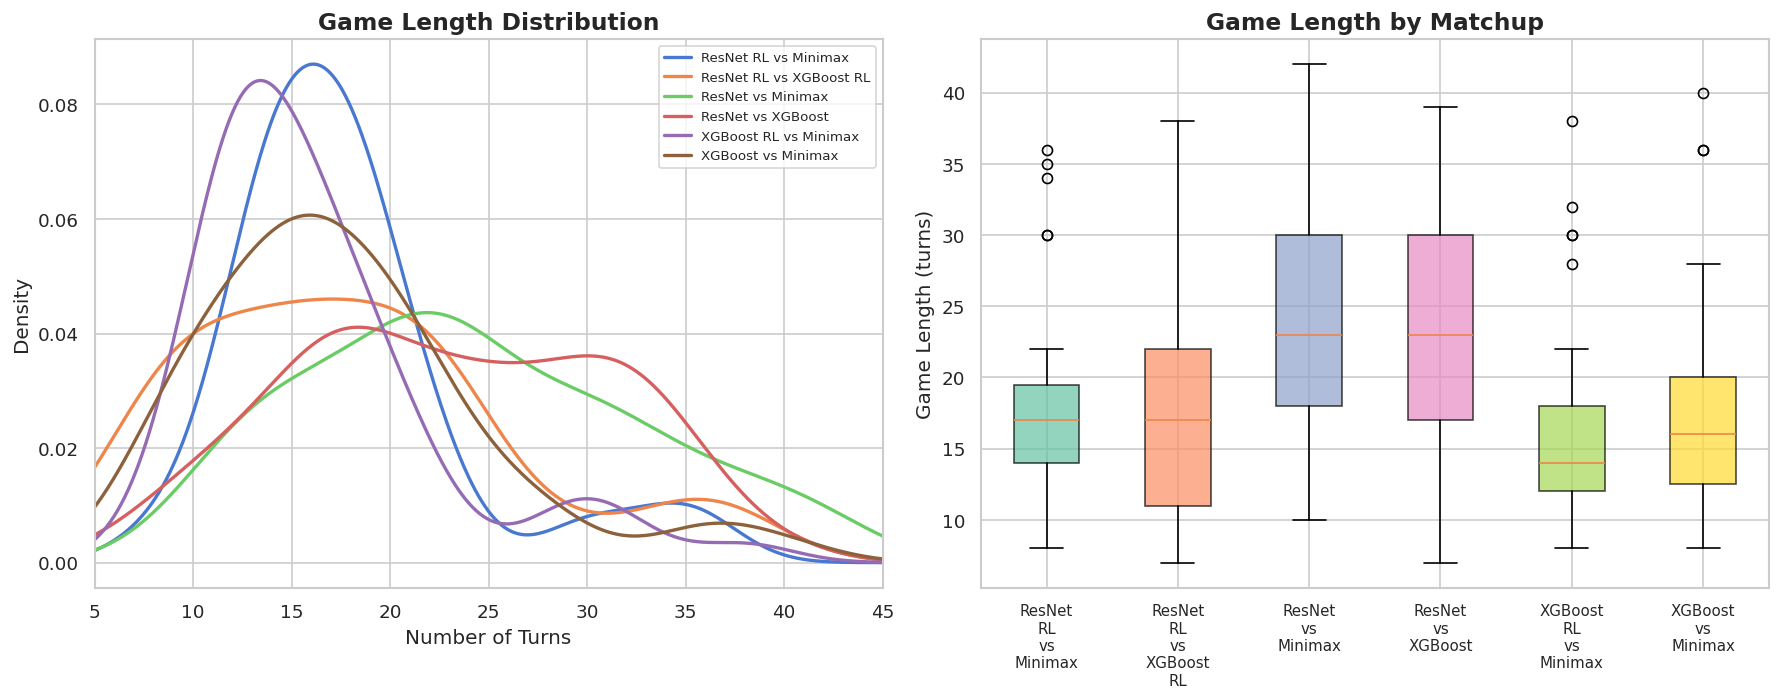

Matchup                                 Mean   Median    Min    Max
-----------------------------------------------------------------
ResNet_RL_vs_Minimax                    17.9     17.0      8     36
ResNet_RL_vs_XGBoost_RL                 18.0     17.0      7     38
ResNet_vs_Minimax                       24.2     23.0     10     42
ResNet_vs_XGBoost                       23.0     23.0      7     39
XGBoost_RL_vs_Minimax                   16.3     14.0      8     38
XGBoost_vs_Minimax                      17.7     16.0      8     40


In [119]:
game_lengths = moves_df.groupby(['Game_ID', 'Matchup'])['Turn_Number'].max().reset_index()
game_lengths.columns = ['Game_ID', 'Matchup', 'Length']

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# KDE plot instead of overlapping histogram
for matchup in matchups:
    mdata = game_lengths[game_lengths['Matchup'] == matchup]['Length']
    label = matchup.replace('_', ' ')
    mdata.plot.kde(ax=axes[0], label=label, linewidth=2, bw_method=0.4)

axes[0].set_xlabel('Number of Turns')
axes[0].set_ylabel('Density')
axes[0].set_title('Game Length Distribution', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=8, loc='upper right')
axes[0].set_xlim(5, 45)

# Box plot per matchup
matchup_lengths = [game_lengths[game_lengths['Matchup'] == m]['Length'].values for m in matchups]
matchup_labels = [m.replace('_', '\n') for m in matchups]
bp = axes[1].boxplot(matchup_lengths, labels=matchup_labels, patch_artist=True)
palette = sns.color_palette('Set2', len(matchups))
for patch, color in zip(bp['boxes'], palette):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1].set_ylabel('Game Length (turns)')
axes[1].set_title('Game Length by Matchup', fontsize=14, fontweight='bold')
axes[1].tick_params(axis='x', labelsize=9)

plt.tight_layout()
plt.show()

print(f'{"Matchup":<35} {"Mean":>8} {"Median":>8} {"Min":>6} {"Max":>6}')
print('-' * 65)
for matchup in matchups:
    gl = game_lengths[game_lengths['Matchup'] == matchup]['Length']
    print(f'{matchup:<35} {gl.mean():>8.1f} {gl.median():>8.1f} {gl.min():>6} {gl.max():>6}')

## 8. Win Rate vs Minimax Benchmark

If games against Minimax are available, this section compares how each
ML model performs against the same fixed-strength opponent — the key
metric for an objective comparative study.

Minimax benchmark matchups found: ['ResNet_RL_vs_Minimax', 'ResNet_vs_Minimax', 'XGBoost_RL_vs_Minimax', 'XGBoost_vs_Minimax']


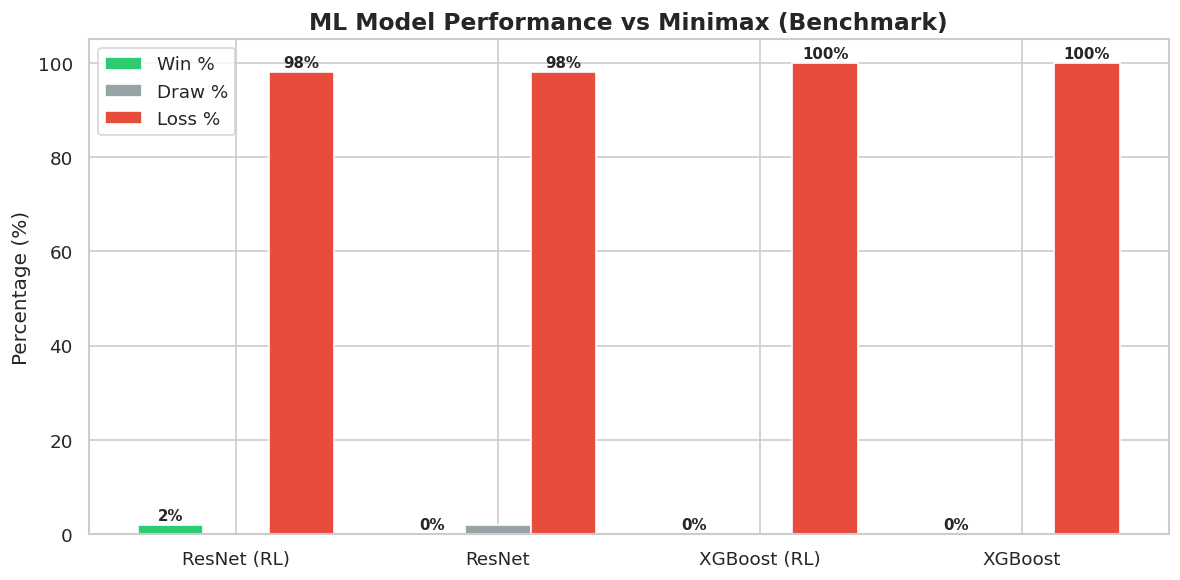


Agent                 Games    Win   Draw   Loss    Win%   Loss%
------------------------------------------------------------
ResNet (RL)              50      1      0     49    2.0%   98.0%
ResNet                   50      0      1     49    0.0%   98.0%
XGBoost (RL)             50      0      0     50    0.0%  100.0%
XGBoost                  50      0      0     50    0.0%  100.0%


In [120]:
# Find matchups that include Minimax
minimax_matchups = results_df[results_df['Winner'].str.contains('Minimax', na=False) |
                              results_df['Matchup'].str.contains('Minimax', na=False)]
minimax_matchup_types = minimax_matchups['Matchup'].unique()

if len(minimax_matchup_types) > 0:
    print('Minimax benchmark matchups found:', list(minimax_matchup_types))

    benchmark = {}
    for matchup in minimax_matchup_types:
        mdf = results_df[results_df['Matchup'] == matchup]
        total = len(mdf)
        # Find the non-Minimax agent
        matchup_agents = moves_df[moves_df['Matchup'] == matchup]['Agent'].unique()
        ml_agent = [a for a in matchup_agents if 'Minimax' not in a]
        if not ml_agent:
            continue
        ml_name = ml_agent[0]

        wins = (mdf['Winner'] == ml_name).sum()
        draws = (mdf['Winner'] == 'Draw').sum()
        losses = total - wins - draws

        benchmark[ml_name] = {
            'matchup': matchup,
            'total': total,
            'wins': wins,
            'draws': draws,
            'losses': losses,
            'win_rate': 100 * wins / total,
            'draw_rate': 100 * draws / total,
            'loss_rate': 100 * losses / total,
        }

    if benchmark:
        bm_agents = list(benchmark.keys())
        fig, ax = plt.subplots(figsize=(10, 5))

        x = np.arange(len(bm_agents))
        w = 0.25
        win_vals = [benchmark[a]['win_rate'] for a in bm_agents]
        draw_vals = [benchmark[a]['draw_rate'] for a in bm_agents]
        loss_vals = [benchmark[a]['loss_rate'] for a in bm_agents]

        ax.bar(x - w, win_vals, w, label='Win %', color='#2ecc71')
        ax.bar(x, draw_vals, w, label='Draw %', color='#95a5a6')
        ax.bar(x + w, loss_vals, w, label='Loss %', color='#e74c3c')

        ax.set_ylabel('Percentage (%)')
        ax.set_title('ML Model Performance vs Minimax (Benchmark)', fontsize=14, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels(bm_agents, fontsize=11)
        ax.legend()
        ax.set_ylim(0, 105)

        for i, a in enumerate(bm_agents):
            ax.text(i - w, win_vals[i] + 1, f'{win_vals[i]:.0f}%', ha='center', fontsize=9, fontweight='bold')
            ax.text(i + w, loss_vals[i] + 1, f'{loss_vals[i]:.0f}%', ha='center', fontsize=9, fontweight='bold')

        plt.tight_layout()
        plt.show()

        # Print table
        print(f'\n{"Agent":<20} {"Games":>6} {"Win":>6} {"Draw":>6} {"Loss":>6} {"Win%":>7} {"Loss%":>7}')
        print('-' * 60)
        for a in bm_agents:
            b = benchmark[a]
            print(f'{a:<20} {b["total"]:>6} {b["wins"]:>6} {b["draws"]:>6} '
                  f'{b["losses"]:>6} {b["win_rate"]:>6.1f}% {b["loss_rate"]:>6.1f}%')
else:
    print('No Minimax benchmark games found.\n'
          'Run AI vs AI with RN v MM and XG v MM matchups to generate benchmark data.')

## 9. Summary Statistics

In [121]:
print('=' * 70)
print('COMPARATIVE ANALYSIS — SUMMARY')
print('=' * 70)

for agent in agents:
    s = agent_stats.get(agent)
    if s is None:
        continue

    times = moves_df[moves_df['Agent'] == agent]['Compute_Time_ms'].dropna()

    print(f'\n--- {agent} ---')
    print(f'  Games Played:   {s["total"]}')
    print(f'  Win Rate:       {s["wins"]}/{s["total"]} ({s["win_rate"]:.1f}%)')
    print(f'  Draw Rate:      {s["draws"]}/{s["total"]} ({s["draw_rate"]:.1f}%)')
    print(f'  Loss Rate:      {s["losses"]}/{s["total"]} ({s["loss_rate"]:.1f}%)')
    print(f'  Avg Time (ms):  {times.mean():.2f}')
    print(f'  Med Time (ms):  {times.median():.2f}')

draws_total = (results_df['Winner'] == 'Draw').sum()
total_games = len(results_df)
all_lengths = game_lengths['Length']

print(f'\n--- Overall ---')
print(f'  Total Games:     {total_games}')
print(f'  Total Draws:     {draws_total} ({100*draws_total/total_games:.1f}%)')
print(f'  Avg Game Length: {all_lengths.mean():.1f} turns')
print(f'  Matchup Types:   {len(matchups)}')
print('=' * 70)

COMPARATIVE ANALYSIS — SUMMARY

--- ResNet (RL) ---
  Games Played:   100
  Win Rate:       37/100 (37.0%)
  Draw Rate:      0/100 (0.0%)
  Loss Rate:      63/100 (63.0%)
  Avg Time (ms):  24.31
  Med Time (ms):  24.38

--- Minimax ---
  Games Played:   200
  Win Rate:       198/200 (99.0%)
  Draw Rate:      1/200 (0.5%)
  Loss Rate:      1/200 (0.5%)
  Avg Time (ms):  49.29
  Med Time (ms):  43.44

--- XGBoost (RL) ---
  Games Played:   100
  Win Rate:       14/100 (14.0%)
  Draw Rate:      0/100 (0.0%)
  Loss Rate:      86/100 (86.0%)
  Avg Time (ms):  7.40
  Med Time (ms):  7.09

--- ResNet ---
  Games Played:   100
  Win Rate:       35/100 (35.0%)
  Draw Rate:      1/100 (1.0%)
  Loss Rate:      64/100 (64.0%)
  Avg Time (ms):  19.44
  Med Time (ms):  20.49

--- XGBoost ---
  Games Played:   100
  Win Rate:       15/100 (15.0%)
  Draw Rate:      0/100 (0.0%)
  Loss Rate:      85/100 (85.0%)
  Avg Time (ms):  6.62
  Med Time (ms):  6.28

--- Overall ---
  Total Games:     300
  Tota